# 🌲 ENSEMBLE LEARNING: BAGGING, BOOSTING & STACKING
## Complete Guide to Heterogeneous Stacking, Random Forest, AdaBoost, GBDT & XGBoost

> **Ensemble Learning Principle**:
> Combining multiple diverse machine learning models reduces variance (bagging), reduces bias (boosting), or harnesses complementary predictive signals (stacking), yielding superior generalization performance compared to any individual base model.

---

### 📚 Structure of This Notebook:
1. **Section 1: Stacking Classifier** (Heterogeneous base estimators: DecisionTree, SVC, LogisticRegression combined via Meta-Learner).
2. **Section 2: Random Forest (Bagging Ensemble)** (Parallel bootstrap aggregation, feature subsampling, unpruned trees).
3. **Section 3: Deep Dive into Out-Of-Bag (OOB) Evaluation** (Theoretical derivation of 36.8% OOB rate, OOB score implementation, decision function probabilities, comparison with 5-fold CV, and error convergence curves).
4. **Section 4: Boosting Classifiers** (AdaBoost, Gradient Boosting, and XGBoost).


In [1]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [2]:
df = sns.load_dataset('iris')

In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
X = df.drop('species', axis=1)
y = df['species']

In [5]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)


In [7]:
base_learners = [
    ('dt', DecisionTreeClassifier(random_state=42)),
    ('svc', SVC(probability=True, kernel='rbf', random_state=42)),
    ('lr', LogisticRegression(max_iter=1000))
]

In [8]:
meta_learner = LogisticRegression(max_iter=1000)


In [9]:
stacking_clf = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5
)

In [10]:
stacking_clf.fit(X_train, y_train)


,estimators,"[('dt', ...), ('svc', ...), ...]"
,final_estimator,LogisticRegre...max_iter=1000)
,cv,5
,stack_method,'auto'
,n_jobs,None
,passthrough,False
,verbose,0
,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2


In [11]:
y_pred = stacking_clf.predict(X_test)

In [12]:
accuracy = accuracy_score(y_test, y_pred)

In [13]:
accuracy

0.9666666666666667

---
## 🌲 Section 2: Random Forest (Bagging Ensemble)

### 📌 Overview:
- **Bagging (Bootstrap Aggregating)**: Creates $B$ bootstrap datasets by randomly sampling $N$ instances **with replacement**. Each tree is trained independently and in parallel on its own bootstrap sample.
- **Random Subspace Method**: At every internal node split, only a random subset of features (typically $\sqrt{p}$) is evaluated, de-correlating individual trees.
- **Aggregation**: Final classification is determined by **majority voting** across all $B$ trees.


In [14]:
from sklearn.ensemble import RandomForestClassifier


In [15]:
rf_model = RandomForestClassifier(
    n_estimators=100,     # number of trees
    max_depth=None,       # let trees grow fully
    random_state=42,

)


In [16]:
rf_model.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [17]:
y_pred = rf_model.predict(X_test)

In [18]:
accuracy = accuracy_score(y_test, y_pred)

In [19]:
accuracy

0.9

---
## 📦 Section 3: Theory of Out-Of-Bag (OOB) Evaluation in Random Forest

### 1. What is Out-Of-Bag (OOB)?
When training a Random Forest with bootstrap sampling (`bootstrap=True`), each individual decision tree is fitted on a bootstrap sample drawn with replacement from the original dataset of $n$ instances.

Because samples are drawn **with replacement**:
- Some training instances appear multiple times in a tree's bootstrap sample.
- Other training instances **never appear at all** in that tree's bootstrap sample.

The instances that are completely omitted from a specific tree's training sample are called the **Out-Of-Bag (OOB) samples** for that tree.

---

### 2. 📐 Mathematical Derivation: Why Exactly ~36.8% of Samples are Out-Of-Bag
Let $n$ be the total number of training samples.

1. **Probability of selection in 1 draw**:
   In any single random pick with replacement, the probability that a specific sample $i$ is chosen is:
   $$P(\text{Selected}) = \frac{1}{n}$$
   Conversely, the probability that sample $i$ is **not chosen** in that single pick is:
   $$P(\text{Not Selected}) = 1 - \frac{1}{n}$$

2. **Probability of non-selection across all $n$ draws**:
   A bootstrap sample consists of $n$ independent draws with replacement. The probability that sample $i$ is **never selected** in any of the $n$ draws is:
   $$P(\text{Sample } i \text{ is OOB}) = \left(1 - \frac{1}{n}\right)^n$$

3. **Asymptotic Limit as $n \to \infty$**:
   Using the standard calculus definition of Euler's number $e = \lim_{n \to \infty} \left(1 + \frac{1}{n}\right)^n$, we have:
   $$\lim_{n \to \infty} \left(1 - \frac{1}{n}\right)^n = e^{-1} = \frac{1}{e} \approx 0.367879 \dots \approx 36.8\%$$

#### 💡 Key Statistical Implication:
- Each decision tree is trained on approximately **63.2%** of unique training observations ($1 - 1/e \approx 63.2\%$).
- The remaining **36.8%** of observations are completely unseen by that tree and serve as an **independent test set** for that specific tree!

---

### 3. ⚙️ How the OOB Score is Calculated (Step-by-Step Algorithm)
The Out-of-Bag evaluation procedure turns these unused samples into an internal, zero-leakage cross-validation mechanism:

For each training instance $(x_i, y_i) \in D_{train}$:
1. **Find OOB Trees**: Identify the subset of trees $\mathcal{B}_i^{OOB}$ in the ensemble where instance $(x_i, y_i)$ was **not** used during training:
   $$\mathcal{B}_i^{OOB} = \{ b \in \{1, \dots, B\} \mid (x_i, y_i) \notin \text{Bootstrap}_b \}$$
2. **Collect Predictions**: Pass $x_i$ exclusively through the trees in $\mathcal{B}_i^{OOB}$.
3. **Aggregate Predictions**:
   - **Classification (Majority Vote / Probability Averaging)**:
     $$\hat{P}(Y = c \mid x_i) = \frac{1}{|\mathcal{B}_i^{OOB}|} \sum_{b \in \mathcal{B}_i^{OOB}} I(\hat{y}_{i, b} = c)$$
     $$\hat{y}_i^{OOB} = \arg\max_{c} \hat{P}(Y = c \mid x_i)$$
   - **Regression (Average)**:
     $$\hat{y}_i^{OOB} = \frac{1}{|\mathcal{B}_i^{OOB}|} \sum_{b \in \mathcal{B}_i^{OOB}} \hat{y}_{i, b}$$
4. **Compute Global OOB Metric**:
   - **Classification**: $\text{OOB Accuracy} = \frac{1}{n} \sum_{i=1}^n I(\hat{y}_i^{OOB} = y_i)$
   - **Regression**: $\text{OOB } R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i^{OOB})^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$

---

### 4. ⚖️ OOB Score vs. Cross-Validation vs. Train/Test Split

| Evaluation Strategy | Data Utilization | Computational Cost | Leakage Risk | Primary Application |
| :--- | :--- | :--- | :--- | :--- |
| **Training Accuracy** | 100% of data | $1 \times$ fit | High (Severely overfits unpruned trees) | Sanity check only |
| **Train / Test Split** | Wastes 20-30% data | $1 \times$ fit | None | Final unbiased model benchmark |
| **$K$-Fold Cross Validation** | Rotates $K$ folds | **$K \times$ full fits** (High compute) | None | Model selection, hyperparameter tuning |
| **Out-Of-Bag (OOB) Score** | **100% data used for training** | **$1 \times$ fit (FREE computation!)** | **Zero leakage** (Evaluated only on out-of-sample trees) | **Ideal for Random Forest / Bagging** |

> **Theorem (Leo Breiman, 2001)**: The Out-of-Bag error estimate is an **unbiased estimator** of generalization error. As the number of trees $B$ grows, OOB error is asymptotically equivalent to Leave-One-Out Cross-Validation (LOOCV), eliminating the need for expensive separate cross-validation folds during model prototyping!


In [20]:
# ==============================================================================
# 1. IMPLEMENTATION: RANDOM FOREST WITH OUT-OF-BAG (OOB) EVALUATION
# ==============================================================================
# Enable Out-of-Bag scoring by setting oob_score=True
rf_oob = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    oob_score=True,        # Built-in Out-of-Bag evaluation
    random_state=42
)

# Fit on training data
rf_oob.fit(X_train, y_train)

# Retrieve Evaluation Metrics
train_acc = accuracy_score(y_train, rf_oob.predict(X_train))
oob_acc = rf_oob.oob_score_
test_acc = accuracy_score(y_test, rf_oob.predict(X_test))

print("=" * 65)
print(f"🌲 Training Set Accuracy (Biased / Memorized) : {train_acc * 100:.2f}%")
print(f"📦 Out-Of-Bag (OOB) Score (Built-in Validation): {oob_acc * 100:.2f}%")
print(f"🎯 Test Set Accuracy (Unseen Holdout Data)    : {test_acc * 100:.2f}%")
print("=" * 65)
print("💡 Key Takeaway: Notice how Training Accuracy is 100% (unpruned trees memorized train data),")
print(f"   while the OOB Score ({oob_acc*100:.2f}%) gives an honest, realistic estimate of generalization")
print(f"   that closely tracks unseen test set performance ({test_acc*100:.2f}%)!")


🌲 Training Set Accuracy (Biased / Memorized) : 100.00%
📦 Out-Of-Bag (OOB) Score (Built-in Validation): 94.17%
🎯 Test Set Accuracy (Unseen Holdout Data)    : 90.00%
💡 Key Takeaway: Notice how Training Accuracy is 100% (unpruned trees memorized train data),
   while the OOB Score (94.17%) gives an honest, realistic estimate of generalization
   that closely tracks unseen test set performance (90.00%)!


In [21]:
# ==============================================================================
# 2. INSPECTING OOB DECISION FUNCTION (PREDICTED CLASS PROBABILITIES)
# ==============================================================================
# rf_oob.oob_decision_function_ has shape (n_samples, n_classes).
# Each row contains class probabilities computed exclusively by trees that left that sample out!
oob_probabilities = rf_oob.oob_decision_function_

import pandas as pd
import numpy as np

oob_analysis_df = pd.DataFrame(
    oob_probabilities,
    columns=[f"P({cls_name})" for cls_name in le.classes_]
)
oob_analysis_df['True_Species'] = le.inverse_transform(y_train)
oob_analysis_df['OOB_Predicted'] = le.inverse_transform(np.argmax(oob_probabilities, axis=1))
oob_analysis_df['Is_Correct'] = oob_analysis_df['True_Species'] == oob_analysis_df['OOB_Predicted']

print("🔍 Sample of Out-Of-Bag Probability Estimates (First 5 Training Instances):")
display(oob_analysis_df.head())

print(f"\nTotal Training Samples Evaluated via OOB: {len(oob_analysis_df)}")
print(f"Correct OOB Classifications: {oob_analysis_df['Is_Correct'].sum()} / {len(oob_analysis_df)} ({oob_analysis_df['Is_Correct'].mean()*100:.2f}%)")


🔍 Sample of Out-Of-Bag Probability Estimates (First 5 Training Instances):


,P(setosa),P(versicolor),P(virginica),True_Species,OOB_Predicted,Is_Correct
0,1.0,0.000000,0.000000,setosa,setosa,True
1,0.0,0.742857,0.257143,virginica,versicolor,False
2,0.0,0.909091,0.090909,versicolor,versicolor,True
3,1.0,0.000000,0.000000,setosa,setosa,True
4,0.0,1.000000,0.000000,versicolor,versicolor,True



Total Training Samples Evaluated via OOB: 120
Correct OOB Classifications: 113 / 120 (94.17%)


In [22]:
# ==============================================================================
# 3. EMPIRICAL BENCHMARK: OOB SCORE VS 5-FOLD CROSS-VALIDATION VS TEST SET
# ==============================================================================
from sklearn.model_selection import cross_val_score

# Run 5-Fold Cross-Validation on the training set
cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X_train, y_train, cv=5
)

benchmark_df = pd.DataFrame({
    'Evaluation Method': [
        'Training Set Accuracy (Biased / Memorized)',
        'Out-Of-Bag (OOB) Score (FREE during 1 fit)',
        '5-Fold Cross-Validation (Mean of 5 full fits)',
        'Test Set Accuracy (Unseen holdout evaluation)'
    ],
    'Accuracy (%)': [
        round(train_acc * 100, 2),
        round(oob_acc * 100, 2),
        round(cv_scores.mean() * 100, 2),
        round(test_acc * 100, 2)
    ],
    'Models Trained': [
        '1 Forest',
        '1 Forest (Zero extra computation)',
        '5 Separate Forests',
        '1 Forest'
    ],
    'Validation Role': [
        'Apparent Error',
        'Built-in Generalization Estimate',
        'Cross-Validation Estimate',
        'True Unseen Holdout Evaluation'
    ]
})

display(benchmark_df)


,Evaluation Method,Accuracy (%),Models Trained,Validation Role
0,Training Set Accuracy (Biased / Memorized),100.00,1 Forest,Apparent Error
1,Out-Of-Bag (OOB) Score (FREE during 1 fit),94.17,1 Forest (Zero extra computation),Built-in Generalization Estimate
2,5-Fold Cross-Validation (Mean of 5 full fits),95.00,5 Separate Forests,Cross-Validation Estimate
3,Test Set Accuracy (Unseen holdout evaluation),90.00,1 Forest,True Unseen Holdout Evaluation


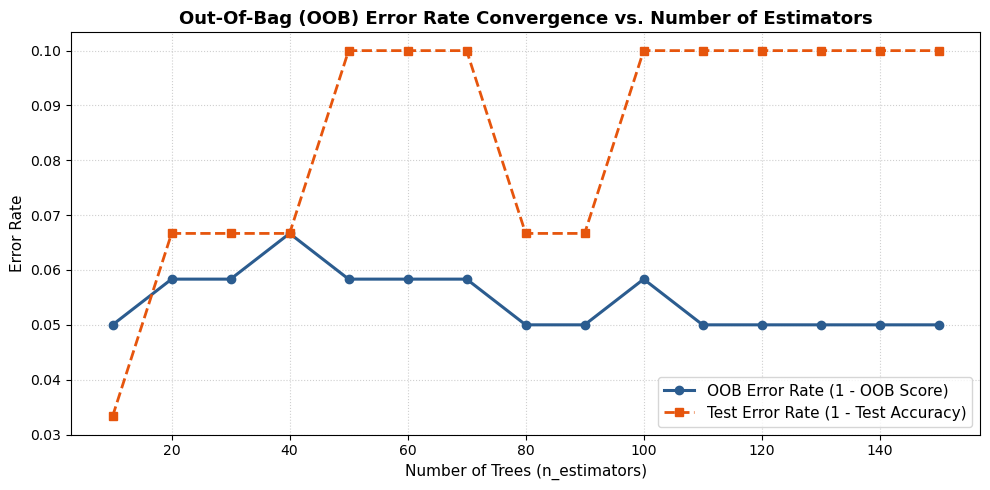

In [23]:
# ==============================================================================
# 4. VISUALIZATION: OOB ERROR CONVERGENCE ACROSS TREE ENSEMBLE SIZE
# ==============================================================================
import matplotlib.pyplot as plt

tree_counts = range(10, 160, 10)
oob_error_rates = []
test_error_rates = []

for n in tree_counts:
    rf_temp = RandomForestClassifier(
        n_estimators=n,
        max_depth=None,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    )
    rf_temp.fit(X_train, y_train)
    oob_error_rates.append(1.0 - rf_temp.oob_score_)
    test_error_rates.append(1.0 - accuracy_score(y_test, rf_temp.predict(X_test)))

plt.figure(figsize=(10, 5))
plt.plot(tree_counts, oob_error_rates, marker='o', color='#2b5c8f', linewidth=2.2, label='OOB Error Rate (1 - OOB Score)')
plt.plot(tree_counts, test_error_rates, marker='s', linestyle='--', color='#e6550d', linewidth=2.0, label='Test Error Rate (1 - Test Accuracy)')
plt.title('Out-Of-Bag (OOB) Error Rate Convergence vs. Number of Estimators', fontsize=13, fontweight='bold')
plt.xlabel('Number of Trees (n_estimators)', fontsize=11)
plt.ylabel('Error Rate', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


---
## ⚡ Section 4: Boosting Classifiers (AdaBoost, Gradient Boosting, XGBoost)


In [24]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier

In [25]:
from xgboost import XGBClassifier

In [26]:
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)

In [27]:
ada_model.fit(X_train,y_train)

,estimator,None
,n_estimators,100
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,42


In [28]:
y_pred = ada_model.predict(X_test)

In [29]:
 accuracy = accuracy_score(y_test, y_pred)

In [30]:
accuracy

0.9333333333333333

In [31]:
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)


In [32]:
gb_model.fit(X_train,y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [33]:
y_pred = gb_model.predict(X_test)

In [34]:
 accuracy = accuracy_score(y_test, y_pred)

In [35]:
accuracy

0.9666666666666667

In [36]:
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, use_label_encoder=False, eval_metric='mlogloss', random_state=42)


In [37]:
xgb_model.fit(X_train, y_train)


C:\Users\ayush\AppData\Roaming\Python\Python313\site-packages\xgboost\training.py:200: UserWarning: [16:21:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'mlogloss'


In [38]:
y_pred = xgb_model.predict(X_test)


In [39]:
 accuracy = accuracy_score(y_test, y_pred)

In [40]:
accuracy

0.9333333333333333